<a href="https://colab.research.google.com/github/Pserrod869/Teachable-Machine/blob/main/teachablemachine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Teachable Machine Practica

<!doctype html>
<html lang="es">
  <head>
    <meta charset="utf-8">
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <meta name="theme-color" content="#f4f7fb">
    <title>Clasificador de imágenes</title>
    <link rel="stylesheet" href="./style.css">
    <script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@1.7.4/dist/tf.min.js"></script>
    <script src="https://cdn.jsdelivr.net/npm/@teachablemachine/image@0.8/dist/teachablemachine-image.min.js"></script>
    <script src="./app.js" defer></script>
  </head>
  <body>
    <main class="app-shell">
      <header class="page-header">
        <p class="eyebrow">CLASIFICADOR CON INTELIGENCIA ARTIFICIAL</p>
        <h1>¿Qué hay en la imagen?</h1>
        <p class="intro">Sube una foto o activa la cámara y el modelo la clasificará.</p>
      </header>

      <section class="classifier" aria-label="Clasificador de imágenes">
        <div class="workspace">
          <div class="media-panel">
            <div class="panel-heading">
              <h2>Prueba una imagen</h2>
              <span class="model-tag">Modelo: Ratón y libreta</span>
            </div>

            <div class="media-frame" id="media-frame">
              <div class="placeholder" id="placeholder">
                <span class="placeholder-icon" aria-hidden="true">✦</span>
                <p>Tu imagen aparecerá aquí</p>
                <span>Usa una foto o la cámara</span>
              </div>
              <img id="image-preview" alt="Imagen seleccionada para clasificar" hidden>
              <div id="webcam-container" hidden></div>
            </div>

            <div class="actions">
              <input id="image-input" class="file-input" type="file" accept="image/*">
              <label class="button button-primary" for="image-input">Elegir imagen</label>
              <button class="button button-secondary" id="start-camera" type="button">Iniciar cámara</button>
              <button class="button button-quiet" id="stop-camera" type="button" hidden>Detener cámara</button>
            </div>
            <p class="camera-note">La cámara requiere permiso del navegador y una conexión local segura (localhost).</p>
          </div>

          <aside class="results-panel" aria-live="polite" aria-atomic="false">
            <div class="panel-heading">
              <h2>Resultado</h2>
              <span class="result-icon" aria-hidden="true">↗</span>
            </div>
            <p class="status" id="status" role="status">Elige una imagen o inicia la cámara para comenzar.</p>
            <div id="predictions" class="predictions">
              <p class="results-placeholder">Las predicciones aparecerán aquí.</p>
            </div>
          </aside>
        </div>
        <footer class="card-footer">
          <span class="status-dot" aria-hidden="true"></span>
          <span>Clasificación ejecutada en tu navegador</span>
        </footer>
      </section>
      <p class="page-footnote">El modelo reconoce las clases con las que fue entrenado. La calidad de la predicción puede variar según la imagen.</p>
    </main>
  </body>
</html>

In [ ]:
:root {
  color-scheme: light;
  font-family: Inter, ui-sans-serif, system-ui, -apple-system, BlinkMacSystemFont, "Segoe UI", sans-serif;
  color: #172238;
  background: #f4f7fb;
  font-synthesis: none;
  text-rendering: optimizeLegibility;
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

* {
  box-sizing: border-box;
}

body {
  min-width: 320px;
  min-height: 100vh;
  margin: 0;
  background:
    radial-gradient(ellipse at 50% 0, rgba(211, 228, 255, 0.55), transparent 48%),
    #f4f7fb;
}

button,
input {
  font: inherit;
}

.app-shell {
  width: min(100% - 40px, 1056px);
  margin: 0 auto;
  padding: 76px 0 36px;
}

.page-header {
  margin-bottom: 32px;
  text-align: center;
}

.eyebrow {
  margin: 0 0 12px;
  color: #526ed0;
  font-size: 0.72rem;
  font-weight: 750;
  letter-spacing: 0.14em;
}

h1,
h2,
p {
  margin-top: 0;
}

h1 {
  margin-bottom: 12px;
  font-size: clamp(2rem, 5vw, 3rem);
  letter-spacing: -0.055em;
  line-height: 1.08;
}

.intro {
  margin-bottom: 0;
  color: #69768a;
  font-size: 1.05rem;
}

.classifier {
  overflow: hidden;
  border: 1px solid #e6ebf2;
  border-radius: 20px;
  background: #fff;
  box-shadow: 0 20px 60px rgba(35, 55, 95, 0.09);
}

.workspace {
  display: grid;
  grid-template-columns: minmax(0, 1.2fr) minmax(260px, 0.8fr);
  gap: 32px;
  padding: 32px;
}

.panel-heading {
  display: flex;
  min-height: 32px;
  align-items: center;
  justify-content: space-between;
  gap: 12px;
  margin-bottom: 18px;
}

.panel-heading h2 {
  margin: 0;
  font-size: 1rem;
  font-weight: 700;
  letter-spacing: -0.02em;
}

.model-tag {
  padding: 6px 9px;
  border-radius: 999px;
  background: #f0f3ff;
  color: #5368bc;
  font-size: 0.7rem;
  font-weight: 650;
  white-space: nowrap;
}

.media-frame {
  display: grid;
  min-height: 300px;
  place-items: center;
  overflow: hidden;
  border: 1px dashed #d6ddea;
  border-radius: 13px;
  background: #f8faff;
}

.placeholder {
  padding: 32px 16px;
  color: #8894a8;
  text-align: center;
}

.placeholder-icon {
  display: grid;
  width: 52px;
  height: 52px;
  place-items: center;
  margin: 0 auto 16px;
  border-radius: 16px;
  background: #eaf0ff;
  color: #5974d1;
  font-size: 1.4rem;
}

.placeholder p {
  margin-bottom: 6px;
  color: #3a4961;
  font-size: 0.93rem;
  font-weight: 650;
}

.placeholder span:last-child {
  font-size: 0.8rem;
}

#image-preview {
  display: block;
  max-width: 100%;
  max-height: 390px;
  object-fit: contain;
}

#webcam-container canvas {
  display: block;
  max-width: 100%;
  height: auto;
}

.actions {
  display: flex;
  flex-wrap: wrap;
  gap: 10px;
  margin-top: 17px;
}

.button {
  display: inline-flex;
  min-height: 43px;
  align-items: center;
  justify-content: center;
  padding: 0 15px;
  border: 1px solid transparent;
  border-radius: 9px;
  cursor: pointer;
  font-size: 0.84rem;
  font-weight: 650;
  text-decoration: none;
  transition: background-color 140ms ease, border-color 140ms ease, transform 140ms ease;
}

.button:hover {
  transform: translateY(-1px);
}

.button:focus-visible,
.file-input:focus-visible + .button {
  outline: 3px solid rgba(87, 111, 211, 0.35);
  outline-offset: 3px;
}

.button-primary {
  background: #536dd0;
  color: #fff;
}

.button-primary:hover {
  background: #455fc0;
}

.button-secondary {
  border-color: #dfe5ef;
  background: #fff;
  color: #34425a;
}

.button-secondary:hover,
.button-quiet:hover {
  background: #f5f7fb;
}

.button-quiet {
  border-color: #e7ebf2;
  background: #fff;
  color: #66738a;
}

.button:disabled {
  cursor: wait;
  opacity: 0.65;
}

.file-input {
  position: absolute;
  width: 1px;
  height: 1px;
  overflow: hidden;
  clip: rect(0, 0, 0, 0);
  white-space: nowrap;
  clip-path: inset(50%);
}

.camera-note {
  margin: 12px 0 0;
  color: #929caf;
  font-size: 0.72rem;
  line-height: 1.5;
}

.results-panel {
  min-height: 300px;
  padding: 20px;
  border: 1px solid #edf0f5;
  border-radius: 13px;
  background: #fbfcfe;
}

.result-icon {
  display: grid;
  width: 30px;
  height: 30px;
  place-items: center;
  border-radius: 9px;
  background: #edf1ff;
  color: #536dd0;
  font-size: 1rem;
}

.status {
  min-height: 40px;
  margin: 0 0 24px;
  color: #7d899d;
  font-size: 0.83rem;
  line-height: 1.5;
}

.status[data-state="success"] {
  color: #344b91;
  font-weight: 650;
}

.status[data-state="error"] {
  color: #b33b4b;
}

.results-placeholder {
  padding: 21px 0;
  border-top: 1px solid #edf0f5;
  color: #a0a9b8;
  font-size: 0.8rem;
}

.prediction {
  margin-top: 19px;
}

.prediction-label {
  display: flex;
  justify-content: space-between;
  gap: 10px;
  margin-bottom: 8px;
  color: #627087;
  font-size: 0.82rem;
}

.prediction-top .prediction-label {
  color: #25385f;
  font-weight: 700;
}

.prediction-value {
  color: #63718a;
  font-variant-numeric: tabular-nums;
}

.prediction-track {
  height: 7px;
  overflow: hidden;
  border-radius: 99px;
  background: #e9edf4;
}

.prediction-bar {
  height: 100%;
  border-radius: inherit;
  background: #91a3e9;
  transition: width 220ms ease;
}

.prediction-top .prediction-bar {
  background: #5b75d3;
}

.card-footer {
  display: flex;
  align-items: center;
  gap: 9px;
  padding: 15px 32px;
  border-top: 1px solid #edf0f5;
  color: #8792a3;
  font-size: 0.75rem;
}

.status-dot {
  width: 7px;
  height: 7px;
  border-radius: 50%;
  background: #65b98b;
  box-shadow: 0 0 0 3px #e8f6ee;
}

.page-footnote {
  max-width: 650px;
  margin: 17px auto 0;
  color: #929caf;
  font-size: 0.74rem;
  line-height: 1.6;
  text-align: center;
}

[hidden] {
  display: none !important;
}

@media (max-width: 760px) {
  .app-shell {
    width: min(100% - 28px, 560px);
    padding-top: 44px;
  }

  .workspace {
    grid-template-columns: 1fr;
    gap: 24px;
    padding: 22px;
  }

  .media-frame,
  .results-panel {
    min-height: 250px;
  }

  .card-footer {
    padding: 14px 22px;
  }
}

@media (max-width: 420px) {
  .workspace {
    padding: 17px;
  }

  .model-tag {
    font-size: 0.64rem;
  }

  .actions .button {
    flex: 1 1 auto;
    padding: 0 11px;
    font-size: 0.78rem;
  }
}

In [ ]:
(() => {
  const MODEL_URL = "./Modelo/model.json";
  const METADATA_URL = "./Modelo/metadata.json";

  const imageInput = document.getElementById("image-input");
  const imagePreview = document.getElementById("image-preview");
  const placeholder = document.getElementById("placeholder");
  const webcamContainer = document.getElementById("webcam-container");
  const startCameraButton = document.getElementById("start-camera");
  const stopCameraButton = document.getElementById("stop-camera");
  const status = document.getElementById("status");
  const predictions = document.getElementById("predictions");

  let model;
  let modelPromise;
  let webcam;
  let animationFrame;
  let imageUrl;
  let predictionRun = 0;

  function setStatus(message, state = "") {
    status.textContent = message;
    status.dataset.state = state;
  }

  function showMedia(kind) {
    placeholder.hidden = true;
    imagePreview.hidden = kind !== "image";
    webcamContainer.hidden = kind !== "camera";
  }

  function loadModel() {
    if (model) return Promise.resolve(model);
    if (!modelPromise) {
      setStatus("Cargando el modelo…");
      modelPromise = tmImage.load(MODEL_URL, METADATA_URL)
        .then((loadedModel) => {
          model = loadedModel;
          return model;
        })
        .catch((error) => {
          modelPromise = undefined;
          throw error;
        });
    }
    return modelPromise;
  }

  function showPredictions(results) {
    const sortedResults = [...results].sort((a, b) => b.probability - a.probability);
    predictions.replaceChildren();

    for (const [index, result] of sortedResults.entries()) {
      const probability = Math.max(0, Math.min(1, result.probability));
      const row = document.createElement("div");
      row.className = `prediction${index === 0 ? " prediction-top" : ""}`;

      const label = document.createElement("div");
      label.className = "prediction-label";
      const name = document.createElement("span");
      name.textContent = result.className;
      const value = document.createElement("span");
      value.className = "prediction-value";
      value.textContent = `${Math.round(probability * 100)}%`;
      label.append(name, value);

      const track = document.createElement("div");
      track.className = "prediction-track";
      const bar = document.createElement("div");
      bar.className = "prediction-bar";
      bar.style.width = `${probability * 100}%`;
      track.append(bar);

      row.append(label, track);
      predictions.append(row);
    }

    const best = sortedResults[0];
    if (best) {
      setStatus(`Predicción principal: ${best.className}`, "success");
    }
  }

  async function classifyImage(image) {
    stopCamera();
    const run = ++predictionRun;
    showMedia("image");
    setStatus("Analizando imagen…");
    try {
      const loadedModel = await loadModel();
      const results = await loadedModel.predict(image);
      if (run === predictionRun) showPredictions(results);
    } catch (error) {
      if (run === predictionRun) {
        setStatus(`No se pudo clasificar la imagen: ${error.message}`, "error");
      }
      console.error("Error al clasificar la imagen:", error);
    }
  }

  function stopCamera() {
    predictionRun += 1;
    if (animationFrame !== undefined) {
      cancelAnimationFrame(animationFrame);
      animationFrame = undefined;
    }
    if (webcam) {
      webcam.stop();
      webcam = undefined;
    }
    webcamContainer.replaceChildren();
    webcamContainer.hidden = true;
    stopCameraButton.hidden = true;
    startCameraButton.hidden = false;
  }

  async function predictFromCamera(run) {
    if (!webcam || run !== predictionRun) return;
    webcam.update();
    try {
      const results = await model.predict(webcam.canvas);
      if (run !== predictionRun) return;
      showPredictions(results);
      animationFrame = requestAnimationFrame(() => predictFromCamera(run));
    } catch (error) {
      if (run === predictionRun) {
        setStatus(`No se pudo analizar la cámara: ${error.message}`, "error");
        stopCamera();
      }
      console.error("Error al analizar la cámara:", error);
    }
  }

  async function startCamera() {
    stopCamera();
    const run = ++predictionRun;
    setStatus("Preparando la cámara…");
    startCameraButton.disabled = true;
    try {
      const loadedModel = await loadModel();
      if (run !== predictionRun) return;
      webcam = new tmImage.Webcam(320, 240, true);
      await webcam.setup();
      if (run !== predictionRun) {
        webcam.stop();
        webcam = undefined;
        return;
      }
      await webcam.play();
      if (run !== predictionRun) {
        webcam.stop();
        webcam = undefined;
        return;
      }
      model = loadedModel;
      showMedia("camera");
      webcamContainer.append(webcam.canvas);
      startCameraButton.hidden = true;
      stopCameraButton.hidden = false;
      setStatus("Cámara activa. Apunta a un objeto para clasificarlo.");
      animationFrame = requestAnimationFrame(() => predictFromCamera(run));
    } catch (error) {
      if (run === predictionRun) {
        setStatus(`No se pudo iniciar la cámara: ${error.message}`, "error");
      }
      console.error("Error al iniciar la cámara:", error);
      if (webcam) {
        webcam.stop();
        webcam = undefined;
      }
    } finally {
      startCameraButton.disabled = false;
    }
  }

  imageInput.addEventListener("change", () => {
    const file = imageInput.files && imageInput.files[0];
    if (!file) return;
    imageInput.value = "";
    if (imageUrl) URL.revokeObjectURL(imageUrl);
    imageUrl = URL.createObjectURL(file);
    imagePreview.onload = () => classifyImage(imagePreview);
    imagePreview.onerror = () => {
      setStatus("No se pudo abrir este archivo como imagen.", "error");
      console.error("No se pudo cargar el archivo de imagen seleccionado.");
    };
    imagePreview.src = imageUrl;
  });

  startCameraButton.addEventListener("click", startCamera);
  stopCameraButton.addEventListener("click", () => {
    stopCamera();
    placeholder.hidden = false;
    setStatus("Cámara detenida. Elige una imagen o vuelve a iniciar la cámara.");
  });

  window.addEventListener("beforeunload", () => {
    stopCamera();
    if (imageUrl) URL.revokeObjectURL(imageUrl);
  });
})();

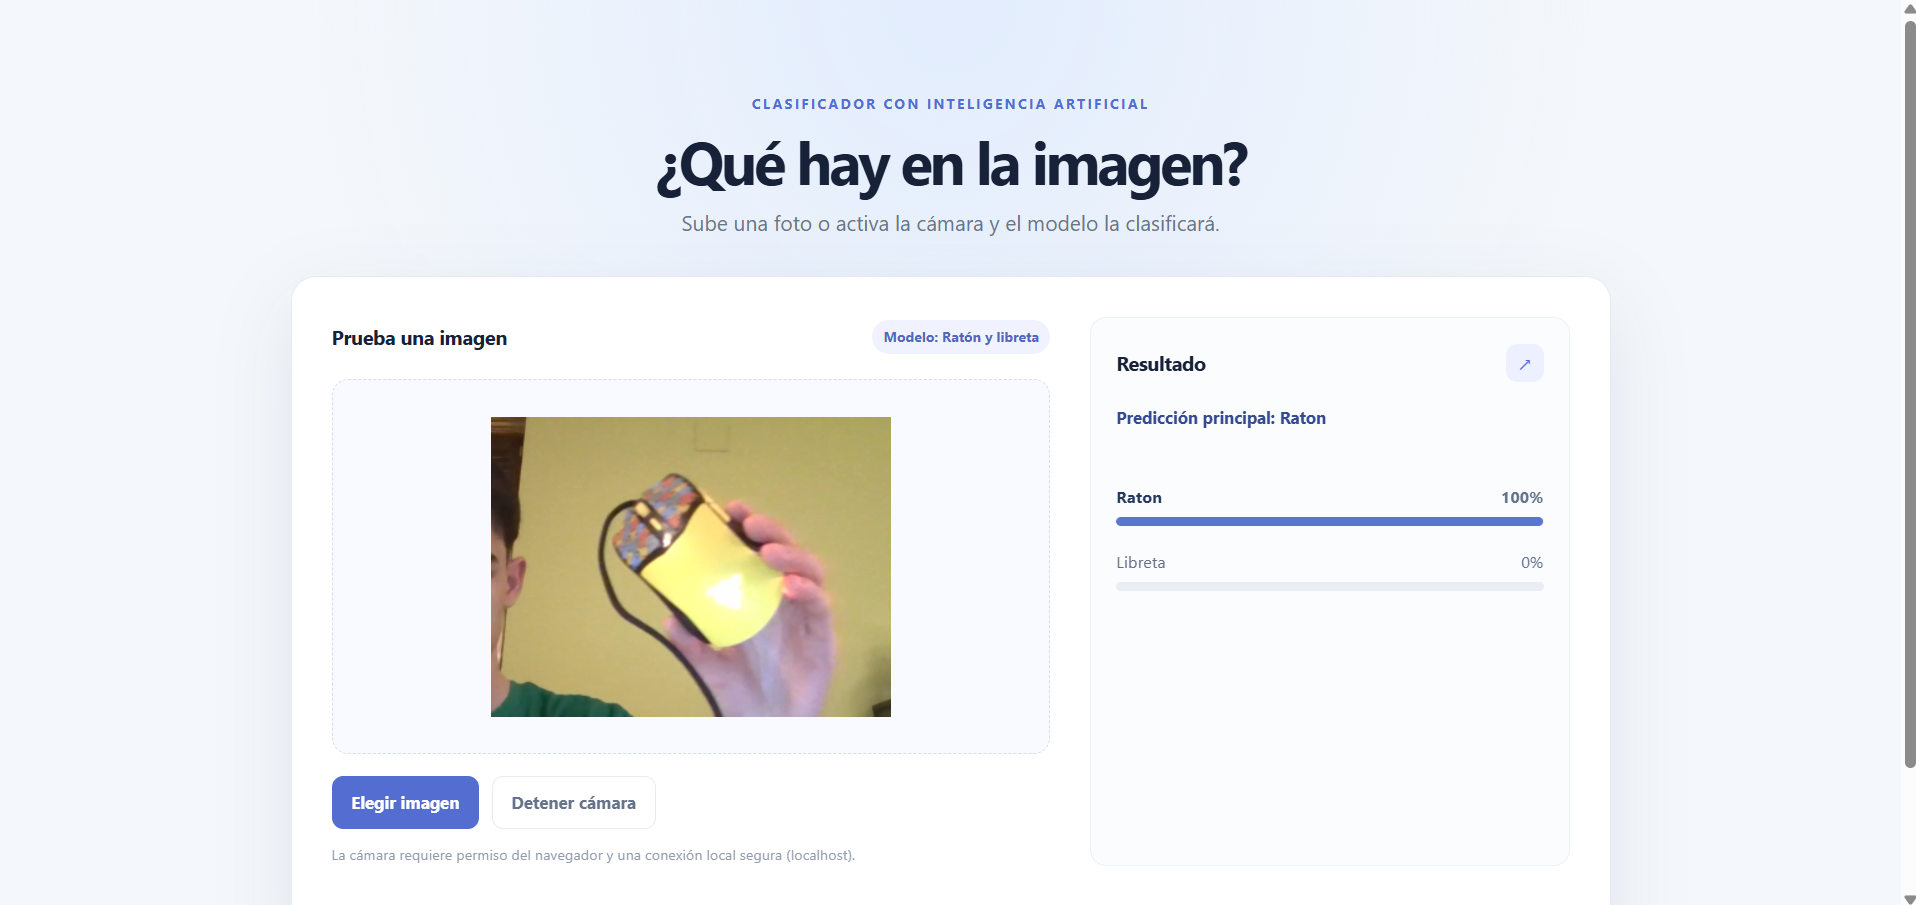

### Resumen de la lógica del código (`app.js`)

He estructurado el código principal de la aplicación (`app.js`) dentro de una función autoejecutable `(() => { ... })();`. Esto lo he hecho como medida de buena práctica para proteger las variables internas (como el modelo o la cámara) y evitar que interfieran con otros elementos de la página web.

La lógica del programa se divide en cuatro bloques fundamentales:

*   **1. Control de ejecuciones seguras:**
    He creado una variable llamada `predictionRun` que funciona como un contador de estado. Cada vez que analizo una foto nueva o enciendo la cámara, este número suma uno. De esta forma, si el modelo tarda en responder pero el usuario ya ha cambiado de imagen, el código compara este número y descarta el resultado viejo, evitando que la pantalla muestre datos desactualizados.

*   **2. Carga optimizada del modelo:**
    En la función `loadModel()`, he programado que los archivos `model.json` y `metadata.json` solo se descarguen en el momento exacto en que se van a usar por primera vez. Este resultado se guarda en una Promesa (`modelPromise`). Así, en futuras predicciones, el código reutiliza el modelo que ya está cargado en la memoria del navegador en lugar de volver a descargarlo desde cero.

*   **3. Análisis en vivo con la cámara:**
    Al ejecutar `startCamera()`, configuro la cámara web, solicito los permisos necesarios y la inyecto en la interfaz. El procesamiento en tiempo real ocurre en `predictFromCamera()`, donde he implementado un bucle usando `requestAnimationFrame`. Esto permite analizar cada fotograma de vídeo de forma continua y fluida hasta que se pulsa el botón de detener y se llama a la función `stopCamera()` para apagar la lente.

*   **4. Renderizado dinámico de resultados:**
    Independientemente de si la entrada es una foto estática o vídeo en vivo, todos los datos pasan por mi función `showPredictions(results)`. Esta función primero ordena los resultados matemáticamente para que la predicción con mayor porcentaje de acierto quede siempre arriba del todo. Posteriormente, limpia los resultados anteriores de la interfaz y genera dinámicamente el HTML necesario para dibujar las barras de probabilidad en la pantalla.